In [7]:
import os
from google.colab import userdata

# Secretsから取得して環境変数にセット
os.environ['KAGGLE_USERNAME'] = userdata.get('USER')
os.environ['KAGGLE_KEY'] = userdata.get('KEY')

In [8]:
!kaggle competitions download -c store-sales-time-series-forecasting

100% 21.4M/21.4M [00:00<00:00, 96.4MB/s]



In [9]:
!unzip /content/store-sales-time-series-forecasting.zip

Archive:  /content/store-sales-time-series-forecasting.zip
  inflating: holidays_events.csv     
  inflating: oil.csv                 
  inflating: sample_submission.csv   
  inflating: stores.csv              
  inflating: test.csv                
  inflating: train.csv               
  inflating: transactions.csv        


In [10]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

# --- 1. TCN Residual Block の定義 ---
def tcn_residual_block(x, filters, kernel_size, dilation_rate, dropout_rate=0.2):
    res = layers.Conv1D(
        filters=filters,
        kernel_size=kernel_size,
        dilation_rate=dilation_rate,
        padding="causal",
        activation="relu"
    )(x)
    res = layers.BatchNormalization()(res)
    res = layers.Dropout(dropout_rate)(res)

    res = layers.Conv1D(
        filters=filters,
        kernel_size=kernel_size,
        dilation_rate=dilation_rate,
        padding="causal",
        activation="linear"
    )(res)
    res = layers.BatchNormalization()(res)
    res = layers.Dropout(dropout_rate)(res)

    # ショートカット接続（次元が合わない場合は1x1畳み込み）
    if x.shape[-1] != filters:
        shortcut = layers.Conv1D(filters, 1, padding="same")(x)
    else:
        shortcut = x

    return layers.Activation("relu")(layers.add([res, shortcut]))

# --- 2. データの準備と時系列分割の設計 ---
train_full = pd.read_csv('train.csv', parse_dates=['date'])
holidays = pd.read_csv('holidays_events.csv', parse_dates=['date'])

# RMSLE対策のための対数変換
train_full['sales_log'] = np.log1p(train_full['sales'])

# 曜日のサイン・コサイン表現（周期性を正しく学習させる）
train_full['day_of_week'] = train_full['date'].dt.dayofweek
train_full['dow_sin'] = np.sin(2 * np.pi * train_full['day_of_week'] / 7.0)
train_full['dow_cos'] = np.cos(2 * np.pi * train_full['day_of_week'] / 7.0)

# 祝日の統合
holiday_list = holidays[~holidays['transferred']][['date', 'type']].copy()
holiday_list['is_holiday'] = 1
holiday_list = holiday_list.groupby('date').agg({'is_holiday': 'max'}).reset_index()
train_full = train_full.merge(holiday_list, on='date', how='left')
train_full['is_holiday'] = train_full['is_holiday'].fillna(0)

# カテゴリエンコーディング
le_store = LabelEncoder()
le_family = LabelEncoder()
train_full['store_idx'] = le_store.fit_transform(train_full['store_nbr'])
train_full['family_idx'] = le_family.fit_transform(train_full['family'])

# プロモーションのスケーリング
scaler_promo = MinMaxScaler()
train_full['promo_scaled'] = scaler_promo.fit_transform(train_full[['onpromotion']])

# 計算負荷削減と直近トレンド学習のため直近1年分のデータを使用
recent_train = train_full[train_full['date'] >= '2016-08-15'].copy()

# シーケンスデータの構築 (Direct Multi-step: 未来16日分を一括予測)
SEQ_LENGTH = 30
PRED_STEPS = 16

# バリデーション設計: 直近16日間 (2017-07-31 〜 2017-08-15) を検証データに分割
val_start_date = pd.to_datetime('2017-07-31')

def create_direct_sequences(data, seq_length, pred_steps, is_validation_split=False):
    X_cont, X_cat_s, X_cat_f, y = [], [], [], []
    for (s, f), group in data.groupby(['store_idx', 'family_idx']):
        vals = group[['sales_log', 'promo_scaled', 'is_holiday', 'dow_sin', 'dow_cos']].values
        dates = group['date'].values
        if len(vals) > (seq_length + pred_steps):
            for i in range(len(vals) - seq_length - pred_steps + 1):
                # 予測開始の初日
                pred_start_date = pd.to_datetime(dates[i + seq_length])
                if is_validation_split:
                    # 検証用: 予測ターゲット期間が検証開始日(2017-07-31)以降に完全に収まるもの
                    if pred_start_date < val_start_date:
                        continue
                else:
                    # 訓練用: 予測ターゲット期間が検証開始日より前のもの
                    if pred_start_date >= val_start_date:
                        continue

                X_cont.append(vals[i : i + seq_length])
                X_cat_s.append(s)
                X_cat_f.append(f)
                y.append(vals[i + seq_length : i + seq_length + pred_steps, 0])

    return np.array(X_cont), np.array(X_cat_s), np.array(X_cat_f), np.array(y)

print("シーケンス作成中...")
X_train_cont, X_train_s, X_train_f, y_train = create_direct_sequences(recent_train, SEQ_LENGTH, PRED_STEPS, is_validation_split=False)
X_val_cont, X_val_s, X_val_f, y_val = create_direct_sequences(recent_train, SEQ_LENGTH, PRED_STEPS, is_validation_split=True)

print(f"Train Samples: {len(y_train)}, Val Samples: {len(y_val)}")

シーケンス作成中...
Train Samples: 568458, Val Samples: 1782


In [11]:
def build_optimized_direct_tcn(seq_len, pred_steps, n_feat, n_stores, n_families):
    # 入力定義
    in_seq = layers.Input(shape=(seq_len, n_feat), name='seq_input')
    in_store = layers.Input(shape=(1,), name='store_input')
    in_family = layers.Input(shape=(1,), name='family_input')

    # Embeddings
    s_emb = layers.Flatten()(layers.Embedding(n_stores, 10)(in_store))
    f_emb = layers.Flatten()(layers.Embedding(n_families, 15)(in_family))

    # TCN層 (GlobalAveragePooling1Dは時間破壊を招くため排除し、最後のタイムステップのみスライス抽出)
    x = tcn_residual_block(in_seq, filters=64, kernel_size=3, dilation_rate=1)
    x = tcn_residual_block(x, filters=64, kernel_size=3, dilation_rate=2)
    x = tcn_residual_block(x, filters=64, kernel_size=3, dilation_rate=4)

    # 最終タイムステップのみを抽出して時間情報を破壊しないようにする
    x_last = layers.Lambda(lambda t: t[:, -1, :])(x)

    # 特徴結合と出力ネットワーク
    concat = layers.Concatenate()([x_last, s_emb, f_emb])
    dense = layers.Dense(128, activation='relu')(concat)
    dense = layers.Dropout(0.2)(dense)

    # 16日間の予測をダイレクトに一括出力
    out = layers.Dense(pred_steps, activation='linear')(dense)

    model = models.Model(inputs=[in_seq, in_store, in_family], outputs=out)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss='mse')
    return model

opt_model = build_optimized_direct_tcn(
    seq_len=SEQ_LENGTH,
    pred_steps=PRED_STEPS,
    n_feat=X_train_cont.shape[2],
    n_stores=train_full['store_idx'].nunique(),
    n_families=train_full['family_idx'].nunique()
)

# 学習実行 (EarlyStopping)
callback = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
history = opt_model.fit(
    [X_train_cont, X_train_s, X_train_f], y_train,
    validation_data=([X_val_cont, X_val_s, X_val_f], y_val),
    epochs=12, batch_size=256, callbacks=[callback]
)

Epoch 1/12
2221/2221 ━━━━━━━━━━━━━━━━━━━━ 46s 13ms/step - loss: 0.5958 - val_loss: 0.2622
Epoch 2/12
2221/2221 ━━━━━━━━━━━━━━━━━━━━ 15s 7ms/step - loss: 0.3820 - val_loss: 0.2508
Epoch 3/12
2221/2221 ━━━━━━━━━━━━━━━━━━━━ 15s 7ms/step - loss: 0.3498 - val_loss: 0.2495
Epoch 4/12
2221/2221 ━━━━━━━━━━━━━━━━━━━━ 15s 7ms/step - loss: 0.3227 - val_loss: 0.2463
Epoch 5/12
2221/2221 ━━━━━━━━━━━━━━━━━━━━ 15s 7ms/step - loss: 0.3036 - val_loss: 0.2448
Epoch 6/12
2221/2221 ━━━━━━━━━━━━━━━━━━━━ 15s 7ms/step - loss: 0.2929 - val_loss: 0.2407
Epoch 7/12
2221/2221 ━━━━━━━━━━━━━━━━━━━━ 15s 7ms/step - loss: 0.2821 - val_loss: 0.2394
Epoch 8/12
2221/2221 ━━━━━━━━━━━━━━━━━━━━ 15s 7ms/step - loss: 0.2760 - val_loss: 0.2431
Epoch 9/12
2221/2221 ━━━━━━━━━━━━━━━━━━━━ 15s 7ms/step - loss: 0.2735 - val_loss: 0.2429
Epoch 10/12
2221/2221 ━━━━━━━━━━━━━━━━━━━━ 15s 7ms/step - loss: 0.2718 - val_loss: 0.2452


In [12]:
# --- 3. 効率的な Direct Multi-step 推論とテストデータ予測 ---
test_df = pd.read_csv('test.csv', parse_dates=['date'])
test_df['day_of_week'] = test_df['date'].dt.dayofweek
test_df['dow_sin'] = np.sin(2 * np.pi * test_df['day_of_week'] / 7.0)
test_df['dow_cos'] = np.cos(2 * np.pi * test_df['day_of_week'] / 7.0)
test_df = test_df.merge(holiday_list, on='date', how='left')
test_df['is_holiday'] = test_df['is_holiday'].fillna(0)
test_df['promo_scaled'] = scaler_promo.transform(test_df[['onpromotion']])
test_df['store_idx'] = le_store.transform(test_df['store_nbr'])
test_df['family_idx'] = le_family.transform(test_df['family'])

# 直近の30日間の履歴を取得してインプットを作成する
unique_series = test_df[['store_idx', 'family_idx']].drop_duplicates().sort_values(['store_idx', 'family_idx'])

current_seqs = []
for _, row in unique_series.iterrows():
    series_history = recent_train[(
train_full['store_idx'] == row['store_idx']) &
                                  (train_full['family_idx'] == row['family_idx'])].iloc[-SEQ_LENGTH:]
    current_seqs.append(series_history[['sales_log', 'promo_scaled', 'is_holiday', 'dow_sin', 'dow_cos']].values)

current_seqs = np.array(current_seqs)
store_ids = unique_series['store_idx'].values
family_ids = unique_series['family_idx'].values

# ダイレクトに全16日分を一発予測（自己回帰による誤差蓄積なし）
print("全時系列一括予測（Direct Multi-step）を実行中...")
preds_log = opt_model.predict([current_seqs, store_ids, family_ids], batch_size=2048, verbose=1)
preds_orig = np.expm1(preds_log) # 対数逆変換

# 予測結果を提出用フォーマットに効率的にマッピング
results = []
for idx, (_, row) in enumerate(unique_series.iterrows()):
    s_idx = row['store_idx']
    f_idx = row['family_idx']

    # 対象店舗・カテゴリのテストデータを日付順に取得
    target_test = test_df[(test_df['store_idx'] == s_idx) & (test_df['family_idx'] == f_idx)].sort_values('date')
    pred_values = preds_orig[idx]

    for j, (test_id, pred_val) in enumerate(zip(target_test['id'].values, pred_values)):
        results.append({'id': test_id, 'sales': max(0.0, pred_val)})

submission_df = pd.DataFrame(results).sort_values('id')
submission_df.to_csv('submission.csv', index=False)
print("\n問題点を解消した submission.csv の作成が完了しました。")
display(submission_df.head(10))

/tmp/ipykernel_882/3545623576.py:17: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  series_history = recent_train[(
/tmp/ipykernel_882/3545623576.py:17: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  series_history = recent_train[(
/tmp/ipykernel_882/3545623576.py:17: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  series_history = recent_train[(
/tmp/ipykernel_882/3545623576.py:17: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  series_history = recent_train[(
/tmp/ipykernel_882/3545623576.py:17: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  series_history = recent_train[(
/tmp/ipykernel_882/3545623576.py:17: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  series_history = recent_train[(
/tmp/ipykernel_882/3545623576.py:17: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  ser

全時系列一括予測（Direct Multi-step）を実行中...
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step

問題点を解消した submission.csv の作成が完了しました。


,id,sales
0,3000888,3.440514
16,3000889,0.058767
32,3000890,2.587291
48,3000891,2057.109863
64,3000892,0.042975
80,3000893,306.940643
96,3000894,8.245772
112,3000895,579.186707
128,3000896,620.707275
144,3000897,118.376328


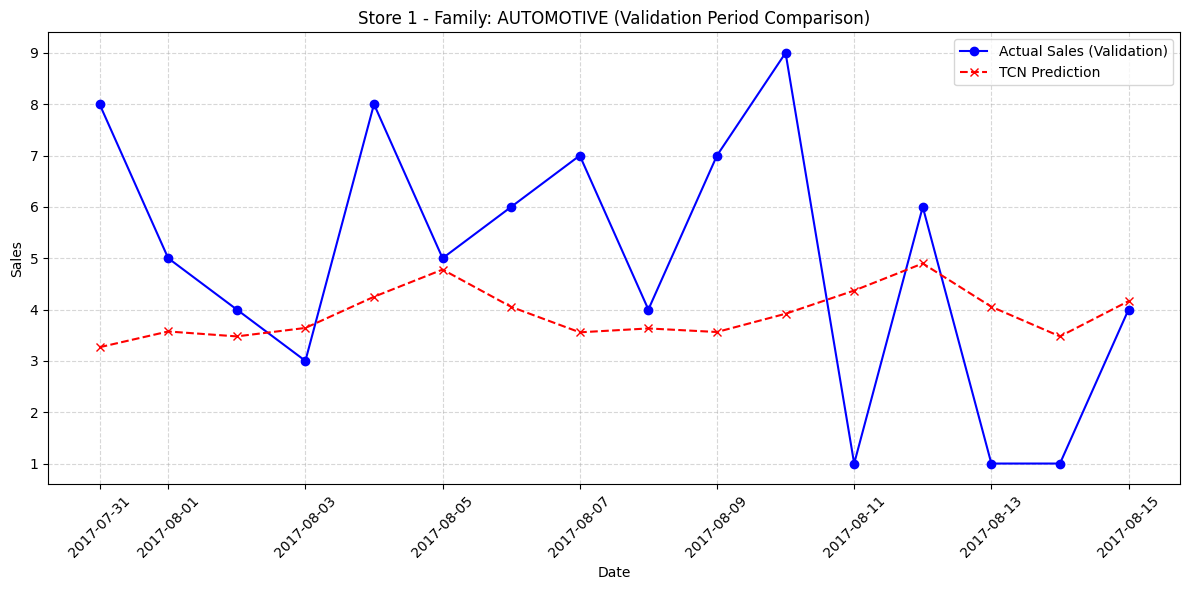

In [13]:
import matplotlib.pyplot as plt

# バリデーション用入力から予測値を取得
val_preds_log = opt_model.predict([X_val_cont, X_val_s, X_val_f], verbose=0)

# 対数逆変換を行い、実数売上スケールに戻す
val_preds_orig = np.expm1(val_preds_log)
val_actuals_orig = np.expm1(y_val)

# 可視化のために特定の系列（例：インデックス0番目の店舗とカテゴリの組み合わせ）を選択
series_idx = 0
s_idx = X_val_s[series_idx]
f_idx = X_val_f[series_idx]

# ラベルの復元
store_num = le_store.inverse_transform([s_idx])[0]
family_name = le_family.inverse_transform([f_idx])[0]

# 日付軸の作成（2017-07-31から16日間）
val_dates = pd.date_range(start="2017-07-31", periods=PRED_STEPS, freq="D")

# グラフ描画
plt.figure(figsize=(12, 6))
plt.plot(val_dates, val_actuals_orig[series_idx], label='Actual Sales (Validation)', marker='o', color='blue')
plt.plot(val_dates, val_preds_orig[series_idx], label='TCN Prediction', marker='x', linestyle='--', color='red')

plt.title(f'Store {store_num} - Family: {family_name} (Validation Period Comparison)')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

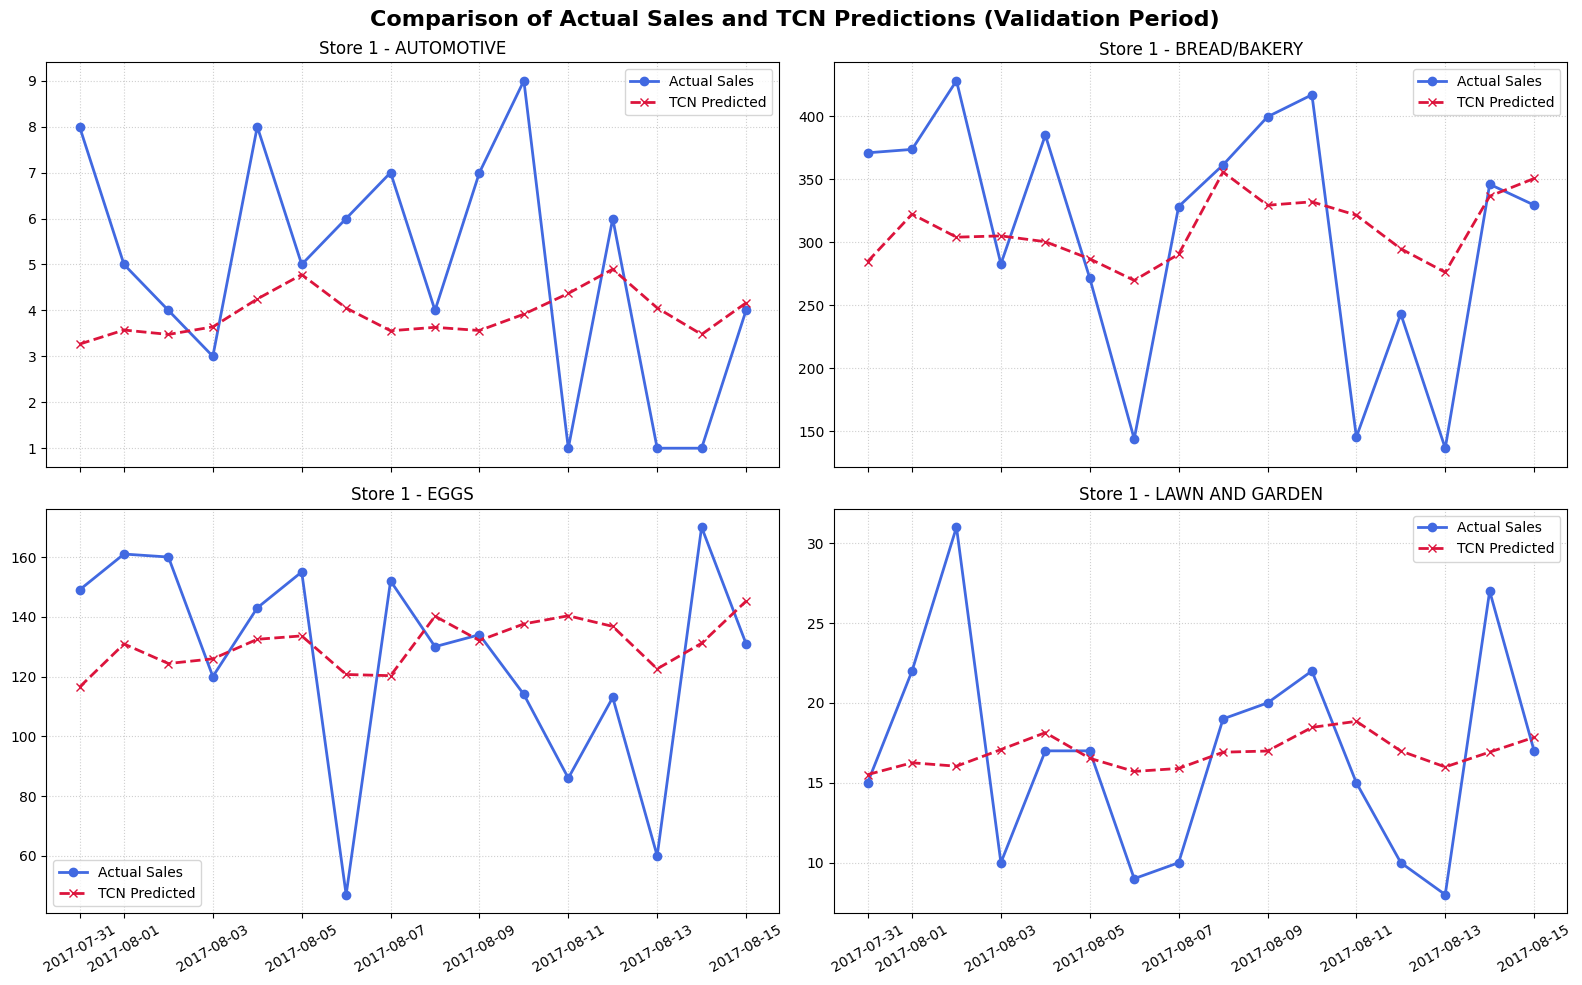

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# バリデーションデータの予測値を取得して指数逆変換
val_preds_log = opt_model.predict([X_val_cont, X_val_s, X_val_f], verbose=0)
val_preds_orig = np.expm1(val_preds_log)
val_actuals_orig = np.expm1(y_val)

# 異なるいくつかのパターンをプロットするために系列をサンプリング（例：異なる4系列）
sample_indices = [0, 5, 10, 20]
val_dates = pd.date_range(start="2017-07-31", periods=PRED_STEPS, freq="D")

fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex=True)
axes = axes.ravel()

for i, idx in enumerate(sample_indices):
    s_idx = X_val_s[idx]
    f_idx = X_val_f[idx]

    store_num = le_store.inverse_transform([s_idx])[0]
    family_name = le_family.inverse_transform([f_idx])[0]

    axes[i].plot(val_dates, val_actuals_orig[idx], label='Actual Sales', marker='o', color='royalblue', linewidth=2)
    axes[i].plot(val_dates, val_preds_orig[idx], label='TCN Predicted', marker='x', linestyle='--', color='crimson', linewidth=2)

    axes[i].set_title(f'Store {store_num} - {family_name}', fontsize=12)
    axes[i].grid(True, linestyle=':', alpha=0.6)
    axes[i].legend(fontsize=10)
    axes[i].tick_params(axis='x', rotation=30)

plt.suptitle('Comparison of Actual Sales and TCN Predictions (Validation Period)', fontsize=16, weight='bold', y=0.98)
plt.tight_layout()
plt.show()